# Next day FRP prediction ML model

In [ ]:
import duckdb
import geopandas as gpd
import polars as pl
import polars.selectors as cs
import pyarrow as pa

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr
from pyproj import Transformer


import lightgbm as lgb
import xgboost as xgb


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)



print("done")


done


## importing the Australian data for MODIS


In [2]:
db = duckdb.connect("../data/australia_fires.duckdb")

print(db.execute("SHOW TABLES").df())

        name
0  all_fires
1   metadata


In [3]:

australia_fires = db.sql("""
    SELECT *
    FROM all_fires
""").pl()

display(australia_fires)

latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
f64,f64,f64,f64,f64,date,str,str,str,i64,f64,f64,f64,str,i64
-25.6877,152.7786,314.4,1.0,1.0,2000-11-01,"""0018""","""Terra""","""MODIS""",56,6.2,293.4,8.7,"""D""",0
-25.3534,152.626,338.4,1.0,1.0,2000-11-01,"""0018""","""Terra""","""MODIS""",88,6.2,296.8,33.9,"""D""",0
-25.5435,152.5442,316.7,1.0,1.0,2000-11-01,"""0018""","""Terra""","""MODIS""",40,6.2,301.2,6.4,"""D""",0
-31.7273,152.0351,306.6,1.0,1.0,2000-11-01,"""0020""","""Terra""","""MODIS""",46,6.2,285.9,4.7,"""D""",0
-25.2241,151.9984,317.1,1.0,1.0,2000-11-01,"""0018""","""Terra""","""MODIS""",61,6.2,300.9,5.8,"""D""",0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
-29.1214,115.3474,324.8,1.1,1.0,2025-12-24,"""1335""","""Terra""","""MODIS""",94,61.03,279.3,0.0,"""N""",0
-29.1476,115.3464,408.6,1.1,1.0,2025-12-24,"""1335""","""Terra""","""MODIS""",100,61.03,306.8,0.0,"""N""",0
-22.46,115.3379,337.7,1.5,1.2,2025-12-24,"""0129""","""Terra""","""MODIS""",86,61.03,309.1,40.9,"""D""",0


In [23]:
australia_fires.shape

(6443441, 15)

In [4]:
print(australia_fires["satellite"].unique())

shape: (2,)
Series: 'satellite' [str]
[
	"Aqua"
	"Terra"
]


In [5]:
modis=australia_fires[["latitude","longitude","brightness","scan","track","acq_date","acq_time","satellite","confidence","version","bright_t31","frp","daynight","type"]]

In [6]:
display(modis.head())

latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,confidence,version,bright_t31,frp,daynight,type
f64,f64,f64,f64,f64,date,str,str,i64,f64,f64,f64,str,i64
-25.6877,152.7786,314.4,1.0,1.0,2000-11-01,"""0018""","""Terra""",56,6.2,293.4,8.7,"""D""",0
-25.3534,152.626,338.4,1.0,1.0,2000-11-01,"""0018""","""Terra""",88,6.2,296.8,33.9,"""D""",0
-25.5435,152.5442,316.7,1.0,1.0,2000-11-01,"""0018""","""Terra""",40,6.2,301.2,6.4,"""D""",0
-31.7273,152.0351,306.6,1.0,1.0,2000-11-01,"""0020""","""Terra""",46,6.2,285.9,4.7,"""D""",0
-25.2241,151.9984,317.1,1.0,1.0,2000-11-01,"""0018""","""Terra""",61,6.2,300.9,5.8,"""D""",0


## importing the Australian data for VIIRS


In [7]:

db_V = duckdb.connect("../data/australia_viirs.duckdb")

print(db_V.execute("SHOW TABLES").df())




                 name
0    extract_metadata
1     import_manifest
2  viirs_observations


In [ ]:

australia_viirs = db_V.sql("""
    SELECT *
    FROM viirs_observations
""").pl()

display(australia_viirs)

latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type,source_country,source_archive,source_member
f64,f64,f64,f64,f64,date,str,str,str,str,f64,f64,f64,str,i64,str,str,str
-41.58427,147.29974,336.6,0.49,0.41,2012-01-20,"""0346""","""N""","""VIIRS""","""l""",2.0,309.06,57.81,"""D""",0,"""Australia""","""viirs1\viirs-snpp_2012_all_cou…","""viirs-snpp/2012/viirs-snpp_201…"
-41.58114,147.29298,367.0,0.49,0.41,2012-01-20,"""0346""","""N""","""VIIRS""","""h""",2.0,311.05,57.81,"""D""",0,"""Australia""","""viirs1\viirs-snpp_2012_all_cou…","""viirs-snpp/2012/viirs-snpp_201…"
-41.57983,147.30508,338.74,0.49,0.41,2012-01-20,"""0346""","""N""","""VIIRS""","""l""",2.0,312.57,34.72,"""D""",0,"""Australia""","""viirs1\viirs-snpp_2012_all_cou…","""viirs-snpp/2012/viirs-snpp_201…"
-41.5767,147.29831,349.52,0.49,0.41,2012-01-20,"""0346""","""N""","""VIIRS""","""n""",2.0,308.48,15.62,"""D""",0,"""Australia""","""viirs1\viirs-snpp_2012_all_cou…","""viirs-snpp/2012/viirs-snpp_201…"
-41.57735,147.29225,354.32,0.49,0.41,2012-01-20,"""0346""","""N""","""VIIRS""","""n""",2.0,312.7,15.62,"""D""",0,"""Australia""","""viirs1\viirs-snpp_2012_all_cou…","""viirs-snpp/2012/viirs-snpp_201…"
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
-32.62585,116.08953,301.17,0.46,0.39,2025-12-31,"""1703""","""N20""","""VIIRS""","""n""",2.0,290.2,0.59,"""N""",0,"""Australia""","""viirs2\viirs-jpss1_2025_all_co…","""viirs-jpss1/2025/viirs-jpss1_2…"
-33.94708,122.51102,302.44,0.43,0.38,2025-12-31,"""1703""","""N20""","""VIIRS""","""n""",2.0,286.48,4.27,"""N""",3,"""Australia""","""viirs2\viirs-jpss1_2025_all_co…","""viirs-jpss1/2025/viirs-jpss1_2…"
-33.9506,122.51035,332.02,0.43,0.38,2025-12-31,"""1703""","""N20""","""VIIRS""","""n""",2.0,290.99,4.27,"""N""",3,"""Australia""","""viirs2\viirs-jpss1_2025_all_co…","""viirs-jpss1/2025/viirs-jpss1_2…"


In [9]:
print(australia_viirs.columns)

['latitude', 'longitude', 'bright_ti4', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_ti5', 'frp', 'daynight', 'type', 'source_country', 'source_archive', 'source_member']


In [10]:
viirs=australia_viirs[['latitude', 'longitude', 'bright_ti4', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'confidence', 'version', 'bright_ti5', 'frp', 'daynight', 'type']]

In [ ]:
viirs.head()

latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,confidence,version,bright_ti5,frp,daynight,type
f64,f64,f64,f64,f64,date,str,str,str,f64,f64,f64,str,i64
-41.58427,147.29974,336.6,0.49,0.41,2012-01-20,"""0346""","""N""","""l""",2.0,309.06,57.81,"""D""",0
-41.58114,147.29298,367.0,0.49,0.41,2012-01-20,"""0346""","""N""","""h""",2.0,311.05,57.81,"""D""",0
-41.57983,147.30508,338.74,0.49,0.41,2012-01-20,"""0346""","""N""","""l""",2.0,312.57,34.72,"""D""",0
-41.5767,147.29831,349.52,0.49,0.41,2012-01-20,"""0346""","""N""","""n""",2.0,308.48,15.62,"""D""",0
-41.57735,147.29225,354.32,0.49,0.41,2012-01-20,"""0346""","""N""","""n""",2.0,312.7,15.62,"""D""",0


# creating the shared grid

In [ ]:


transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:6933",
    always_xy=True
)

def create_grid(df, sensor, cell_size=5000):

    # Remove invalid coordinates
    df = df.filter(
        pl.col("latitude").is_between(-90, 90) &
        pl.col("longitude").is_between(-180, 180)
    )

    # Convert coordinates into meters
    x, y = transformer.transform(
        df["longitude"].to_numpy(),
        df["latitude"].to_numpy()
    )

    # Assign each observation to a grid cell
    df = df.with_columns([
        pl.Series("grid_x", np.floor(x / cell_size).astype(np.int64)),
        pl.Series("grid_y", np.floor(y / cell_size).astype(np.int64)),
        pl.lit(sensor).alias("sensor")
    ])

    return df

In [32]:
modis_grid = create_grid(modis, "MODIS")
viirs_grid = create_grid(viirs, "VIIRS")

In [33]:
modis_grid.head()

latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,confidence,version,bright_t31,frp,daynight,type,grid_x,grid_y,sensor
f64,f64,f64,f64,f64,date,str,str,i64,f64,f64,f64,str,i64,i64,i64,str
-25.6877,152.7786,314.4,1.0,1.0,2000-11-01,"""0018""","""Terra""",56,6.2,293.4,8.7,"""D""",0,2948,-635,"""MODIS"""
-25.3534,152.626,338.4,1.0,1.0,2000-11-01,"""0018""","""Terra""",88,6.2,296.8,33.9,"""D""",0,2945,-627,"""MODIS"""
-25.5435,152.5442,316.7,1.0,1.0,2000-11-01,"""0018""","""Terra""",40,6.2,301.2,6.4,"""D""",0,2943,-631,"""MODIS"""
-31.7273,152.0351,306.6,1.0,1.0,2000-11-01,"""0020""","""Terra""",46,6.2,285.9,4.7,"""D""",0,2933,-770,"""MODIS"""
-25.2241,151.9984,317.1,1.0,1.0,2000-11-01,"""0018""","""Terra""",61,6.2,300.9,5.8,"""D""",0,2933,-624,"""MODIS"""


In [34]:
def aggregate_grid(df):

    return (
        df.group_by([
            "grid_x",
            "grid_y",
            "acq_date",
            "daynight"
        ])
        .agg([
            pl.len().alias("fire_count"),
            pl.col("frp").mean().alias("avg_frp"),
            pl.col("frp").sum().alias("total_frp"),
            pl.col("frp").max().alias("max_frp")
        ])
    )

modis_daily = aggregate_grid(modis_grid)
viirs_daily = aggregate_grid(viirs_grid)

In [35]:
comparison = modis_daily.join(
    viirs_daily,
    on=["grid_x", "grid_y", "acq_date", "daynight"],
    how="full",
    suffix="_viirs",
    coalesce=True
)

comparison = comparison.rename({
    "fire_count": "modis_count",
    "avg_frp": "modis_avg_frp",
    "total_frp": "modis_total_frp",
    "max_frp": "modis_max_frp",
    "fire_count_viirs": "viirs_count",
    "avg_frp_viirs": "viirs_avg_frp",
    "total_frp_viirs": "viirs_total_frp",
    "max_frp_viirs": "viirs_max_frp"
})

display(comparison.head(20))

grid_x,grid_y,acq_date,daynight,modis_count,modis_avg_frp,modis_total_frp,modis_max_frp,viirs_count,viirs_avg_frp,viirs_total_frp,viirs_max_frp
i64,i64,date,str,u32,f64,f64,f64,u32,f64,f64,f64
2598,-304,2019-09-22,"""D""",null,null,null,null,2,8.545,17.09,9.26
2502,-390,2012-05-14,"""D""",null,null,null,null,6,8.49,50.94,11.93
2889,-649,2022-06-17,"""D""",null,null,null,null,3,3.536667,10.61,3.98
2379,-470,2018-04-26,"""D""",null,null,null,null,3,10.246667,30.74,15.1
2416,-414,2014-04-24,"""D""",1,12.0,12.0,12.0,5,6.228,31.14,8.99
…,…,…,…,…,…,…,…,…,…,…,…
2514,-421,2023-05-19,"""N""",null,null,null,null,1,0.46,0.46,0.46
2554,-319,2019-09-13,"""D""",null,null,null,null,1,2.52,2.52,2.52
2404,-561,2025-11-05,"""N""",1,54.3,54.3,54.3,9,13.093333,117.84,35.56


In [36]:
comparison.write_parquet(
    "../data/modis_viirs_5km_comparison.parquet"
)

In [37]:
modis = modis.filter(
    pl.col("acq_date").is_between(
        pl.date(2013, 1, 1),
        pl.date(2024, 12, 31)
    )
)

viirs = viirs.filter(
    pl.col("acq_date").is_between(
        pl.date(2013, 1, 1),
        pl.date(2024, 12, 31)
    )
)


In [39]:
plot_data = comparison.filter(
    pl.col("viirs_avg_frp").is_not_null() &
    pl.col("modis_avg_frp").is_not_null()
)

x = plot_data["viirs_avg_frp"].to_numpy()
y = plot_data["modis_avg_frp"].to_numpy()

## comparing the average frp per day/cell/daynight between MODIS and VIIRS

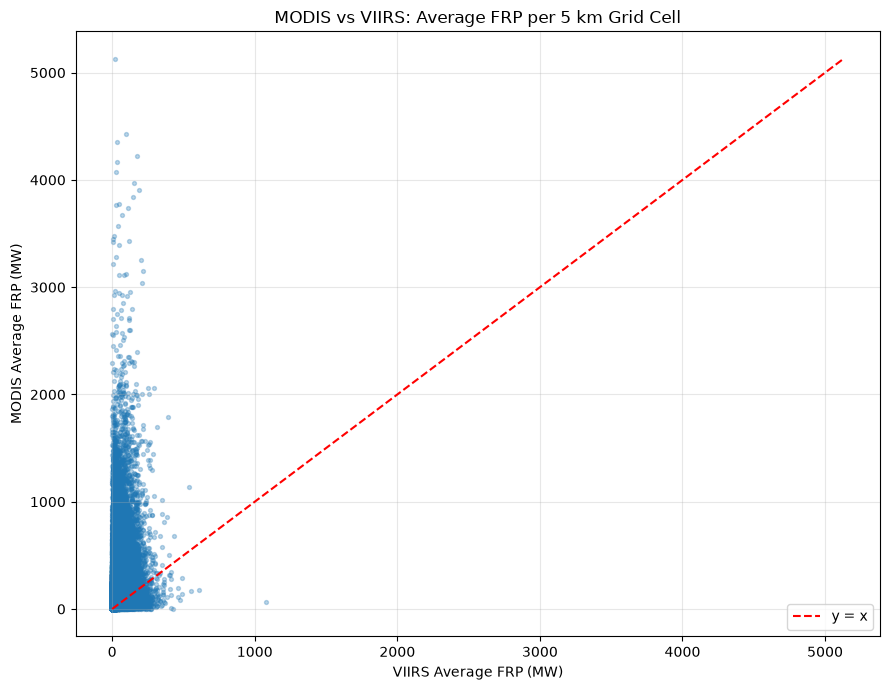

In [40]:
plt.figure(figsize=(9, 7))

plt.scatter(
    x,
    y,
    alpha=0.3,
    s=8
)

# Reference line: VIIRS FRP = MODIS FRP
max_val = max(x.max(), y.max())

plt.plot(
    [0, max_val],
    [0, max_val],
    "r--",
    label="y = x"
)

plt.xlabel("VIIRS Average FRP (MW)")
plt.ylabel("MODIS Average FRP (MW)")
plt.title("MODIS vs VIIRS: Average FRP per 5 km Grid Cell")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

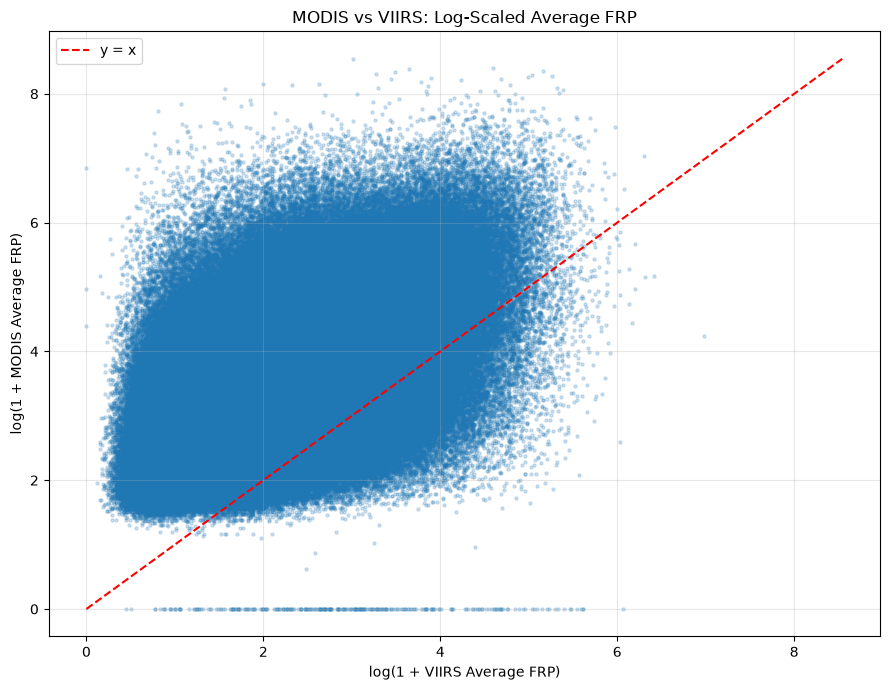

In [ ]:
    # Keep nonnegative, finite FRP values
mask = (
    np.isfinite(x) & np.isfinite(y) &
    (x >= 0) & (y >= 0)
)

x_log = np.log1p(x[mask])
y_log = np.log1p(y[mask])

plt.figure(figsize=(9, 7))

plt.scatter(x_log, y_log, alpha=0.2, s=5)

max_val = max(x_log.max(), y_log.max())

plt.plot(
    [0, max_val],
    [0, max_val],
    "r--",
    label="y = x"
)

plt.xlabel("log(1 + VIIRS Average FRP)")
plt.ylabel("log(1 + MODIS Average FRP)")
plt.title("MODIS vs VIIRS: Log-Scaled Average FRP")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

/var/folders/kq/82b66zsj4rdgvsnvg1bx10d80000gn/T/ipykernel_5782/2356817919.py:16: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/Users/leenisa/Documents/GitHub/Astra-Lost-In-Space/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


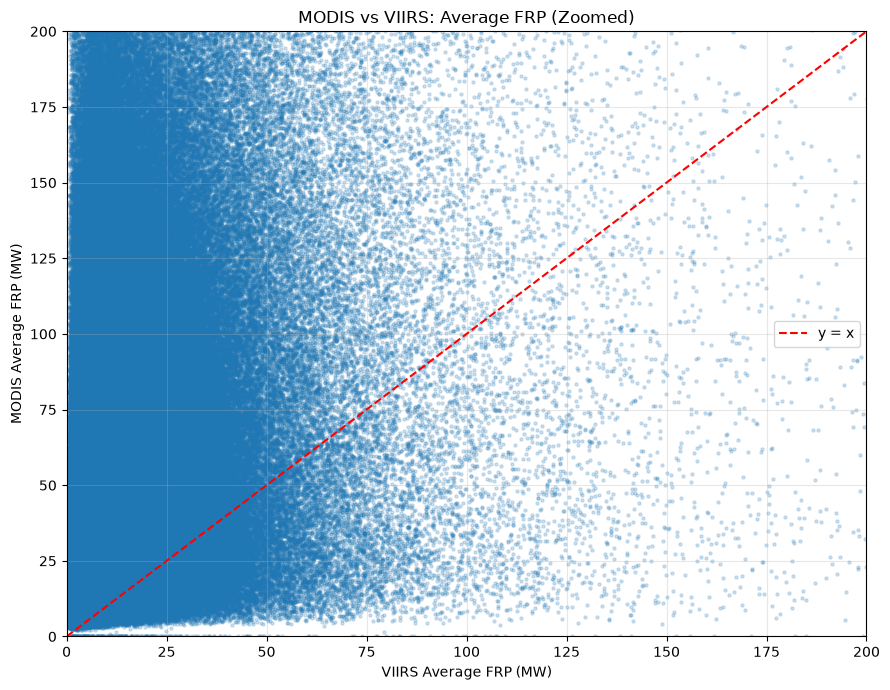

In [42]:
plt.figure(figsize=(9, 7))

plt.scatter(x, y, alpha=0.2, s=5)

plt.plot([0, 200], [0, 200], "r--", label="y = x")

plt.xlim(0, 200)
plt.ylim(0, 200)

plt.xlabel("VIIRS Average FRP (MW)")
plt.ylabel("MODIS Average FRP (MW)")
plt.title("MODIS vs VIIRS: Average FRP (Zoomed)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

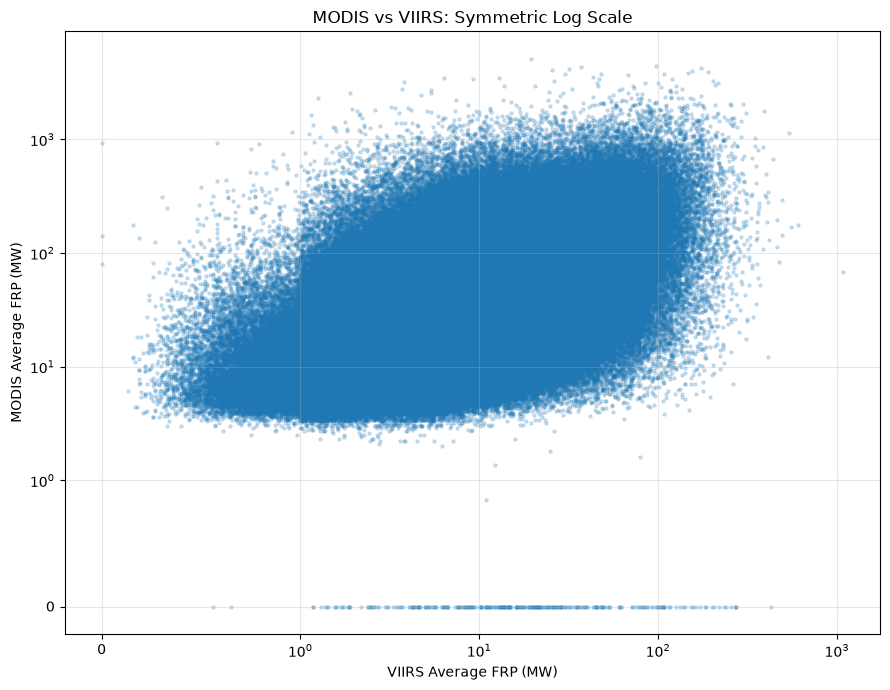

In [43]:
plt.figure(figsize=(9, 7))

plt.scatter(x, y, alpha=0.2, s=5)

plt.xscale("symlog", linthresh=1)
plt.yscale("symlog", linthresh=1)

plt.xlabel("VIIRS Average FRP (MW)")
plt.ylabel("MODIS Average FRP (MW)")
plt.title("MODIS vs VIIRS: Symmetric Log Scale")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:

plot_data = comparison.filter(
    pl.col("viirs_avg_frp").is_not_null() &
    pl.col("modis_avg_frp").is_not_null() &
    pl.col("viirs_avg_frp").is_finite() &
    pl.col("modis_avg_frp").is_finite() &
    (pl.col("viirs_avg_frp") >= 0) &
    (pl.col("modis_avg_frp") >= 0)
)

x = plot_data["viirs_avg_frp"].to_numpy()
y = plot_data["modis_avg_frp"].to_numpy()

In [56]:
x_log = np.log1p(x)
y_log = np.log1p(y)

X = x_log.reshape(-1, 1)

model = LinearRegression()
model.fit(X, y_log)

y_pred = model.predict(X)

In [57]:
r, p_value = pearsonr(x_log, y_log)

r2 = r2_score(y_log, y_pred)

print(f"Pearson correlation (r): {r:.4f}")
print(f"R²: {r2:.4f}")
print(f"Slope: {model.coef_[0]:.4f}")
print(f"Intercept: {model.intercept_:.4f}")
print(f"P-value: {p_value:.4g}")
print(f"Matched grid observations: {len(x):,}")

Pearson correlation (r): 0.5537
R²: 0.3066
Slope: 0.6442
Intercept: 1.9575
P-value: 0
Matched grid observations: 1,260,878


 after trying different scales we concluded that there were no trend between the average FRP values of MODIS and VIIRS. 
 and there were no linear relationship (R^2 is very small)

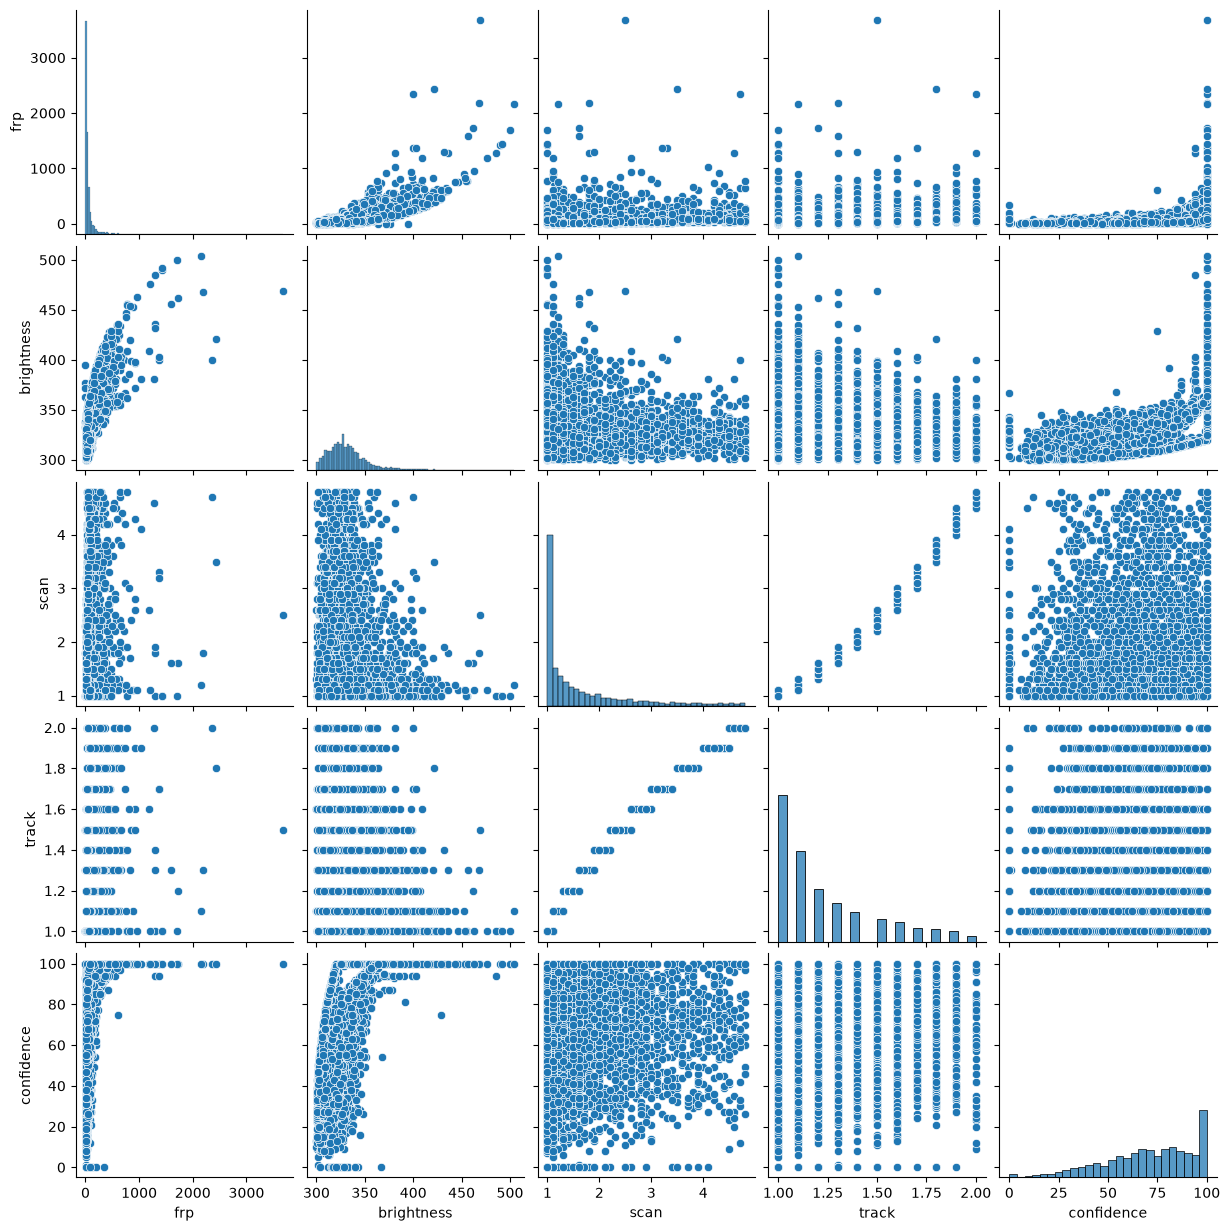

In [67]:
features = ["frp", "brightness", "scan", "track", "confidence"]

plot_df = modis.select(features).sample(
    n=min(5000, modis.height),
    seed=42
).to_pandas()

sns.pairplot(plot_df, diag_kind="hist")
plt.show()

## correlation matrix for the MODIS' features

latitude,longitude,brightness,scan,track,confidence,version,bright_t31,frp,type
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1.0,-0.252762,-0.020122,0.001503,0.002347,-0.069103,0.045141,0.132798,-0.080693,-0.080033
-0.252762,1.0,-0.117685,-0.06933,-0.069889,-0.066226,-0.003621,-0.21718,-0.065984,0.001098
-0.020122,-0.117685,1.0,-0.085766,-0.087769,0.579679,-0.004464,0.652198,0.647247,-0.051404
0.001503,-0.06933,-0.085766,1.0,0.983673,-0.076973,0.007043,-0.133076,0.250235,-0.024385
0.002347,-0.069889,-0.087769,0.983673,1.0,-0.078345,0.007664,-0.134833,0.244915,-0.025337
-0.069103,-0.066226,0.579679,-0.076973,-0.078345,1.0,0.016248,0.249044,0.313943,-0.040798
0.045141,-0.003621,-0.004464,0.007043,0.007664,0.016248,1.0,-0.020054,0.012993,-0.00954
0.132798,-0.21718,0.652198,-0.133076,-0.134833,0.249044,-0.020054,1.0,0.28168,-0.049013
-0.080693,-0.065984,0.647247,0.250235,0.244915,0.313943,0.012993,0.28168,1.0,-0.020121


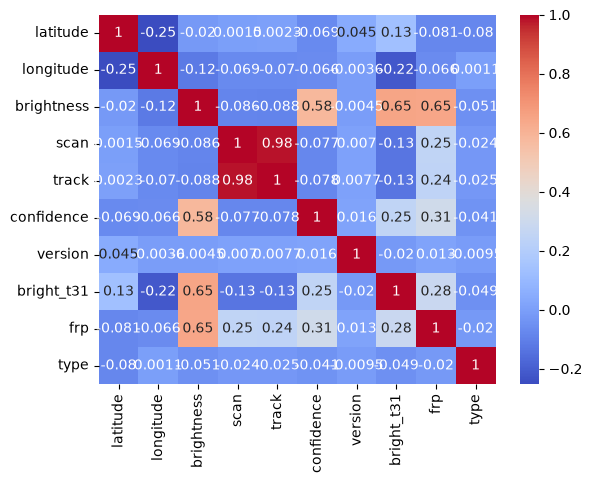

In [ ]:


numeric_df = modis.select(cs.numeric())

corr = numeric_df.corr()

display(corr)

corr = numeric_df.corr()

sns.heatmap(
    corr.to_numpy(),
    annot=True,
    xticklabels=corr.columns,
    yticklabels=corr.columns,
    cmap="coolwarm"
)

plt.show()

## the correlation between the common features between MODIS and VIIRS

In [72]:
modis_agg = (
    modis_grid.group_by(["grid_x", "grid_y", "acq_date", "daynight"])
    .agg([
        pl.col("latitude").mean().alias("modis_latitude"),
        pl.col("longitude").mean().alias("modis_longitude"),
        pl.col("brightness").mean().alias("modis_brightness"),
        pl.col("scan").mean().alias("modis_scan"),
        pl.col("track").mean().alias("modis_track"),
        pl.col("bright_t31").mean().alias("modis_bright_t31"),
        pl.col("frp").mean().alias("modis_frp"),
    ])
)

In [73]:
viirs_agg = (
    viirs_grid.group_by(["grid_x", "grid_y", "acq_date", "daynight"])
    .agg([
        pl.col("latitude").mean().alias("viirs_latitude"),
        pl.col("longitude").mean().alias("viirs_longitude"),
        pl.col("bright_ti4").mean().alias("viirs_bright_ti4"),
        pl.col("scan").mean().alias("viirs_scan"),
        pl.col("track").mean().alias("viirs_track"),
        pl.col("bright_ti5").mean().alias("viirs_bright_ti5"),
        pl.col("frp").mean().alias("viirs_frp"),
    ])
)

In [74]:
paired = modis_agg.join(
    viirs_agg,
    on=["grid_x", "grid_y", "acq_date", "daynight"],
    how="inner"
)

In [75]:
modis_features = [
    "modis_latitude",
    "modis_longitude",
    "modis_brightness",
    "modis_scan",
    "modis_track",
    "modis_bright_t31",
    "modis_frp"
]

viirs_features = [
    "viirs_latitude",
    "viirs_longitude",
    "viirs_bright_ti4",
    "viirs_scan",
    "viirs_track",
    "viirs_bright_ti5",
    "viirs_frp"
]

In [76]:
df_corr = paired.select(modis_features + viirs_features).to_pandas()

In [77]:
corr_matrix = pd.DataFrame(index=viirs_features, columns=modis_features, dtype=float)

for v in viirs_features:
    for m in modis_features:
        corr_matrix.loc[v, m] = df_corr[m].corr(df_corr[v])

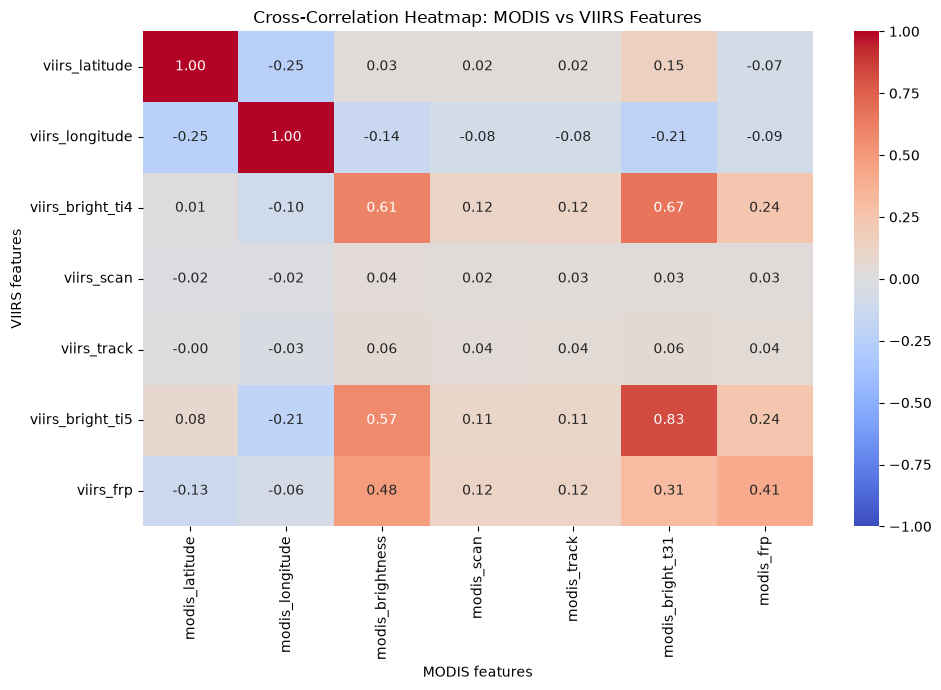

In [78]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.xlabel("MODIS features")
plt.ylabel("VIIRS features")
plt.title("Cross-Correlation Heatmap: MODIS vs VIIRS Features")
plt.tight_layout()
plt.show()

# LIGHTGBM REGRESSION for predicting next day FRP value

In [ ]:

features = [
    "modis_brightness",
    "modis_bright_t31",
    "modis_frp",
    "viirs_bright_ti4",
    "viirs_bright_ti5",
    "viirs_frp"
]

keys = ["grid_x", "grid_y", "acq_date"]

In [ ]:
modis_data = modis_grid.with_columns(
    pl.col("acq_date").cast(pl.Date)
)

viirs_data = viirs_grid.with_columns(
    pl.col("acq_date").cast(pl.Date)
)

In [ ]:
modis_history = (
    modis_data
    .filter(pl.col("acq_date") < pl.date(2012, 1, 1))
    .with_columns(
        pl.col("acq_date").dt.month().alias("month")
    )
    .group_by(["grid_x", "grid_y", "month"])
    .agg([
        pl.col("brightness")
          .mean().alias("modis_brightness"),

        pl.col("bright_t31")
          .mean().alias("modis_bright_t31"),

        pl.col("frp")
          .mean().alias("modis_frp")
    ])
)

if modis_history.is_empty():
    raise ValueError(
        "No historical MODIS data before 2012. "
        "Use your original MODIS grid dataset."
    )


In [ ]:
viirs_daily = (
    viirs_data
    .filter(pl.col("acq_date") >= pl.date(2012, 1, 1))
    .group_by(keys)
    .agg([
        pl.col("bright_ti4")
          .mean().alias("viirs_bright_ti4"),

        pl.col("bright_ti5")
          .mean().alias("viirs_bright_ti5"),

        pl.col("frp")
          .mean().alias("viirs_frp")
    ])
    .sort(["grid_x", "grid_y", "acq_date"])
)


In [ ]:
# tomorrow's FRP is the target variable for prediction.

future = (
    viirs_daily
    .select(keys + ["viirs_frp"])
    .rename({"viirs_frp": "frp_tomorrow"})
    .with_columns(
        pl.col("acq_date")
        .dt.offset_by("-1d")
        .alias("origin_date")
    )
    .drop("acq_date")
)

dataset = (
    viirs_daily
    .rename({"acq_date": "origin_date"})
    .join(
        future,
        on=["grid_x", "grid_y", "origin_date"],
        how="inner"
    )
    .with_columns([
        pl.col("origin_date").dt.month().alias("month"),
        pl.col("origin_date")
          .dt.offset_by("1d")
          .alias("target_date")
    ])
    .join(
        modis_history,
        on=["grid_x", "grid_y", "month"],
        how="left"
    )
)

# FRP target must be finite and nonnegative for log1p.
# Missing predictors can remain null (LightGBM handles them).
dataset = dataset.filter(
    pl.col("frp_tomorrow").is_finite() &
    (pl.col("frp_tomorrow") >= 0)
)

print("Dataset:", dataset.shape)
display(dataset.head())



In [ ]:
# CHRONOLOGICAL SPLIT

train = dataset.filter(
    pl.col("target_date") < pl.date(2022, 1, 1)
)

val = dataset.filter(
    pl.col("target_date").is_between(
        pl.date(2022, 1, 1),
        pl.date(2024, 12, 31)
    )
)

test = dataset.filter(
    pl.col("target_date").is_between(
        pl.date(2025, 1, 1),
        pl.date(2026, 11, 15)
    )
)

for name, part in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(name, part.shape)
    if part.is_empty():
        raise ValueError(f"{name} dataset is empty.")


In [ ]:
#PREPARE INPUTS

X_train = train.select(features).to_pandas()
X_val = val.select(features).to_pandas()
X_test = test.select(features).to_pandas()

# Replace nonfinite predictor values with missing values
for X in [X_train, X_val, X_test]:
    X.replace([np.inf, -np.inf], np.nan, inplace=True)

y_train = train["frp_tomorrow"].to_numpy()
y_val = val["frp_tomorrow"].to_numpy()
y_test = test["frp_tomorrow"].to_numpy()

# Log transform to reduce the influence of extreme FRP
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)


In [ ]:
# TRAIN LIGHTGBM REGRESSION

model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=50,
    random_state=42,
    verbosity=-1
)

model.fit(
    X_train,
    y_train_log,
    eval_set=[(X_val, y_val_log)],
    eval_metric="l2",
    callbacks=[
        lgb.early_stopping(50),
        lgb.log_evaluation(100)
    ]
)


In [ ]:
# PREDICT TOMORROW'S FRP

y_pred_log = model.predict(X_test)

# Convert predictions back to MW
y_pred = np.maximum(np.expm1(y_pred_log), 0)


In [ ]:
#EVALUATION

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Persistence baseline: tomorrow's FRP = today's FRP
baseline = X_test["viirs_frp"].to_numpy()
valid_baseline = np.isfinite(baseline)

print("\nLIGHTGBM RESULTS")
print("--------------------------")
print(f"MAE:  {mae:.4f} MW")
print(f"RMSE: {rmse:.4f} MW")
print(f"R²:   {r2:.4f}")

if valid_baseline.any():
    print("\nPERSISTENCE BASELINE")
    print("--------------------------")
    print(
        "MAE:",
        mean_absolute_error(
            y_test[valid_baseline],
            baseline[valid_baseline]
        )
    )
    print(
        "LightGBM MAE on same rows:",
        mean_absolute_error(
            y_test[valid_baseline],
            y_pred[valid_baseline]
        )
    )


In [ ]:
# PREDICTED VS ACTUAL PLOT

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.25,
    s=7
)

max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [0, max_value],
    [0, max_value],
    "r--",
    label="Perfect prediction"
)

plt.xscale("symlog", linthresh=1)
plt.yscale("symlog", linthresh=1)

plt.xlabel("Actual Tomorrow VIIRS FRP (MW)")
plt.ylabel("Predicted Tomorrow VIIRS FRP (MW)")
plt.title("LightGBM: Next-Day FRP Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# FEATURE IMPORTANCE

importance = pd.DataFrame({
    "feature": features,
    "importance": model.feature_importances_
}).sort_values("importance")

plt.figure(figsize=(9, 5))

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.xlabel("Split Importance")
plt.title("LightGBM Feature Importance")
plt.tight_layout()
plt.show()



In [ ]:
# SAVE PREDICTIONS


results = (
    test.select([
        "grid_x",
        "grid_y",
        "origin_date",
        "target_date",
        "viirs_frp",
        "frp_tomorrow"
    ])
    .with_columns(
        pl.Series("predicted_frp", y_pred)
    )
)

results.write_parquet(
    "../data/lightgbm_frp_predictions.parquet"
)

display(results.head(20))

print("Completed!")

In [85]:
baseline = X_test["viirs_frp"].to_numpy()

mask = np.isfinite(baseline)

print("LightGBM MAE:",
      mean_absolute_error(y_test[mask], y_pred[mask]))

print("Persistence MAE:",
      mean_absolute_error(y_test[mask], baseline[mask]))

print("LightGBM R²:",
      r2_score(y_test[mask], y_pred[mask]))

print("Persistence R²:",
      r2_score(y_test[mask], baseline[mask]))

LightGBM MAE: 4.165389475247069
Persistence MAE: 5.886153249867708
LightGBM R²: 0.008450910409037893
Persistence R²: -0.7364226972326999


In [ ]:

# Use the training-set median, not the test-set median
median_frp = np.median(y_train)

median_pred = np.full_like(
    y_test,
    median_frp,
    dtype=float
)

print("Median baseline MAE:",
      mean_absolute_error(y_test, median_pred))

print("Median baseline R²:",
      r2_score(y_test, median_pred))

print("LightGBM MAE:",
      mean_absolute_error(y_test, y_pred))

Median baseline MAE: 4.364880249278629
Median baseline R²: -0.06127594074962084
LightGBM MAE: 4.165389475247069


# XGBOOST REGRESSION for predicting next day FRP value

Dataset: (1364720, 12)


grid_x,grid_y,origin_date,viirs_bright_ti4,viirs_bright_ti5,viirs_frp,frp_tomorrow,month,target_date,modis_brightness,modis_bright_t31,modis_frp
i64,i64,date,f64,f64,f64,f64,i8,date,f64,f64,f64
2189,-601,2019-12-02,349.296429,302.62,16.918571,15.11,12,2019-12-03,null,null,null
2189,-600,2019-12-01,305.872,289.698,0.804,27.331818,12,2019-12-02,null,null,null
2189,-600,2019-12-02,355.318182,307.902273,27.331818,11.083333,12,2019-12-03,null,null,null
2189,-599,2019-12-01,326.03,291.244286,4.688571,15.758824,12,2019-12-02,null,null,null
2190,-600,2019-12-02,353.867692,305.745,77.363462,27.978889,12,2019-12-03,null,null,null


Train (919747, 12)
Validation (334225, 12)
Test (110748, 12)
[0]	validation_0-rmse:0.67216
[100]	validation_0-rmse:0.63850
[200]	validation_0-rmse:0.63706
[300]	validation_0-rmse:0.63662
[400]	validation_0-rmse:0.63636
[500]	validation_0-rmse:0.63618
[600]	validation_0-rmse:0.63604
[700]	validation_0-rmse:0.63598
[800]	validation_0-rmse:0.63589
[900]	validation_0-rmse:0.63583
[999]	validation_0-rmse:0.63579
Best iteration: 993

XGBOOST RESULTS
--------------------------
MAE:  4.1651 MW
RMSE: 8.7082 MW
R²:   0.0088

PERSISTENCE BASELINE
--------------------------
MAE: 5.886153249867708
R²: -0.7364226972326999


,Model,MAE,RMSE,R2
0,LightGBM,4.165389,8.709595,0.008451
1,XGBoost,4.165118,8.708217,0.008765


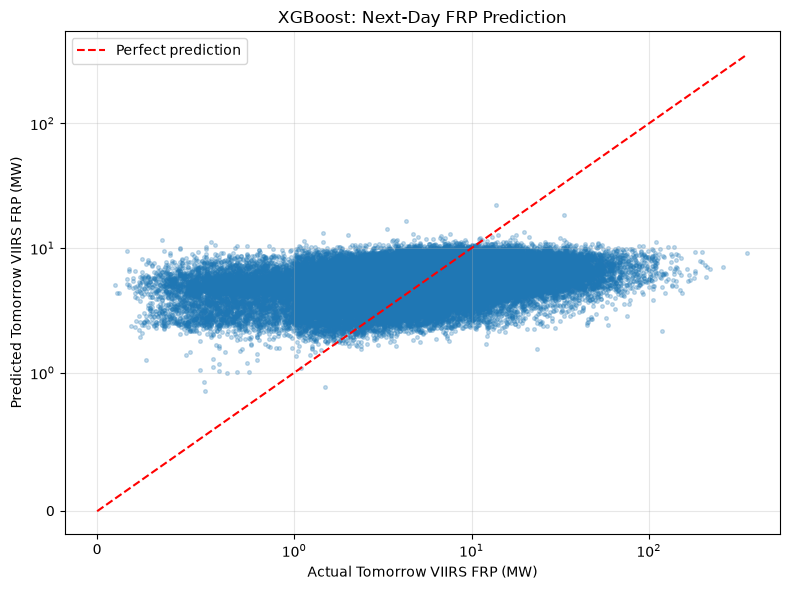

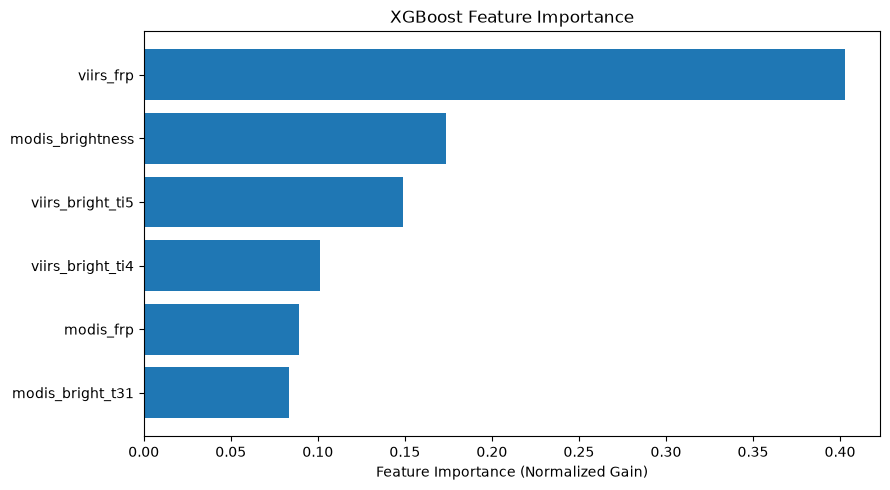

grid_x,grid_y,origin_date,target_date,viirs_frp,frp_tomorrow,predicted_frp_xgb
i64,i64,date,date,f64,f64,f32
2195,-614,2025-05-15,2025-05-16,1.07,2.896667,3.556032
2200,-550,2025-03-05,2025-03-06,9.97,41.702727,7.304169
2200,-549,2025-03-04,2025-03-05,3.65875,19.952347,5.105111
2200,-549,2025-03-05,2025-03-06,19.952347,21.025833,8.280543
2201,-550,2025-03-05,2025-03-06,13.436667,18.663333,7.814594
…,…,…,…,…,…,…
2205,-664,2025-11-15,2025-11-16,17.904286,36.919496,8.603324
2205,-664,2025-11-16,2025-11-17,36.919496,34.4375,10.479069
2205,-663,2025-11-16,2025-11-17,2.165,17.601333,5.60736



XGBoost pipeline completed!


In [ ]:

# TRAIN XGBOOST REGRESSION

model_xgb = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="rmse",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1
)

model_xgb.fit(
    X_train,
    y_train_log,
    eval_set=[(X_val, y_val_log)],
    verbose=100
)

print("Best iteration:", model_xgb.best_iteration)


In [ ]:

# PREDICT TOMORROW'S FRP

y_pred_log = model_xgb.predict(X_test)

# Convert predictions back to MW
y_pred_xgb = np.maximum(np.expm1(y_pred_log), 0)


In [ ]:

# EVALUATION

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb)
)
r2_xgb = r2_score(y_test, y_pred_xgb)

print("\nXGBOOST RESULTS")
print("--------------------------")
print(f"MAE:  {mae_xgb:.4f} MW")
print(f"RMSE: {rmse_xgb:.4f} MW")
print(f"R²:   {r2_xgb:.4f}")

# Persistence baseline
baseline = X_test["viirs_frp"].to_numpy()
valid_baseline = np.isfinite(baseline)

if valid_baseline.any():
    print("\nPERSISTENCE BASELINE")
    print("--------------------------")

    print(
        "MAE:",
        mean_absolute_error(
            y_test[valid_baseline],
            baseline[valid_baseline]
        )
    )

    print(
        "R²:",
        r2_score(
            y_test[valid_baseline],
            baseline[valid_baseline]
        )
    )


In [ ]:

# COMPARE WITH LIGHTGBM

# Reuses y_pred from your previously trained LightGBM,
# if it exists and matches the same test rows.
if "y_pred" in globals() and len(y_pred) == len(y_test):
    comparison_models = pd.DataFrame({
        "Model": ["LightGBM", "XGBoost"],
        "MAE": [
            mean_absolute_error(y_test, y_pred),
            mae_xgb
        ],
        "RMSE": [
            np.sqrt(mean_squared_error(y_test, y_pred)),
            rmse_xgb
        ],
        "R2": [
            r2_score(y_test, y_pred),
            r2_xgb
        ]
    })

    display(comparison_models)


In [ ]:

# PREDICTED VS ACTUAL PLOT


plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_xgb,
    alpha=0.25,
    s=7
)

max_value = max(y_test.max(), y_pred_xgb.max())

plt.plot(
    [0, max_value],
    [0, max_value],
    "r--",
    label="Perfect prediction"
)

plt.xscale("symlog", linthresh=1)
plt.yscale("symlog", linthresh=1)

plt.xlabel("Actual Tomorrow VIIRS FRP (MW)")
plt.ylabel("Predicted Tomorrow VIIRS FRP (MW)")
plt.title("XGBoost: Next-Day FRP Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# FEATURE IMPORTANCE

importance_xgb = pd.DataFrame({
    "feature": features,
    "importance": model_xgb.feature_importances_
}).sort_values("importance")

plt.figure(figsize=(9, 5))

plt.barh(
    importance_xgb["feature"],
    importance_xgb["importance"]
)

plt.xlabel("Feature Importance (Normalized Gain)")
plt.title("XGBoost Feature Importance")
plt.tight_layout()
plt.show()



In [ ]:
# SAVE PREDICTIONS

results_xgb = (
    test.select([
        "grid_x",
        "grid_y",
        "origin_date",
        "target_date",
        "viirs_frp",
        "frp_tomorrow"
    ])
    .with_columns(
        pl.Series("predicted_frp_xgb", y_pred_xgb)
    )
)

results_xgb.write_parquet(
    "../data/xgboost_frp_predictions.parquet"
)

model_xgb.save_model(
    "../data/xgboost_frp_model.json"
)

display(results_xgb.head(20))

print("\nXGBoost pipeline completed!")
